# Chapter 27 — Counterparty Credit Risk and Capital

Every worked example in the chapter, recomputed, Figure 27.1 regenerated, and the SA-CCR formula
built as a small calculator so its pieces can be moved one at a time. Each number is printed beside
the value the chapter prints, so a figure that drifted is visible rather than merely wrong.

| Section | What it reproduces | Example |
|---|---|---|
| 1 | The exposure profile of a swap: EE, PFE and the margined curve, Figure 27.1 | — |
| 2 | What netting is worth | 27.1 |
| 3 | SA-CCR on one swap, in, at and out of the money, with and without margin | 27.2 |
| 4 | The maturity factor, the 111-day cap, and partial offset across buckets | — |
| 5 | Capital under three regimes, and why everything moved to clearing | 27.3 |
| 6 | Where SA-CCR and the internal model meet; the meaning of alpha | — |
| 7 | What wrong-way correlation costs | 27.4 |
| 8 | The leverage ratio crossover, and a bank's capital stack | 27.5 |
| 9 | What a CDS hedge does to a loan's capital | 27.6 |
| 10 | The Archegos arithmetic | case study |

Everything is closed form. Amounts are in millions of dollars unless a label says otherwise.

NumPy, SciPy and Matplotlib.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from math import exp, pi, sqrt
from scipy.integrate import quad
from scipy.optimize import minimize_scalar
from scipy.stats import norm

N, phi = norm.cdf, norm.pdf
BAD = []

# The book's figure palette, from preamble.tex: exampleframe for the primary series,
# snapshotframe for the contrast one. Series are distinguished by dash pattern as well as
# color, because the book prints in grayscale.
BLUE, AMBER = "#28466E", "#78551E"
plt.rcParams.update({"figure.figsize": (6.4, 3.4), "axes.grid": True,
                     "grid.alpha": 0.25, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 9})


def show(label, got, printed, tol=5e-3):
    """Print a computed value beside the one the chapter prints. `tol` is absolute."""
    ok = abs(got - printed) <= tol
    if not ok:
        BAD.append(label)
    print("%-46s %12.5f   book %11.5f   %s" % (label, got, printed, "ok" if ok else "DIFFERS"))

## 1. The exposure profile of a swap — Figure 27.1

Under a driftless normal rate with volatility $\sigma$, a par swap's value at $t$ is its remaining
annuity, about $T-t$ per unit notional, times the rate move, normal with standard deviation
$\sigma\sqrt{t}$. So the 95th-percentile PFE is $(T-t)\,1.645\,\sigma\sqrt{t}$ and the expected
exposure is the same product with $1/\sqrt{2\pi} = 0.40$ in place of $1.645$. Diffusion and the
shrinking number of payments balance at $t = T/3$.

Under daily variation margin only the move over the ten-day margin period of risk can accumulate, so
$\sqrt{t}$ becomes $\sqrt{10/250}$: no hump, and already positive at inception, when the swap is worth
nothing and no margin has been posted.

hump of (T - t) sqrt(t), years (T/3)                1.66667   book     1.66667   ok
PFE at the hump, $m                                 7.07895   book     7.08000   ok
EE at the hump, $m                                  1.71677   book     1.72000   ok
PFE / EE, N^-1(0.95) sqrt(2 pi)                     4.12340   book     4.12000   ok
margined PFE at inception, $m                       1.64500   book     1.65000   ok
EEPE, $m                                            1.17023   book     1.17000   ok
alpha x EEPE, $m                                    1.63832   book     1.64000   ok
peak with 5% discounting, years                     1.75912   book     1.76000   ok
height fall with 5% discounting, %                  7.78635   book     7.80000   ok


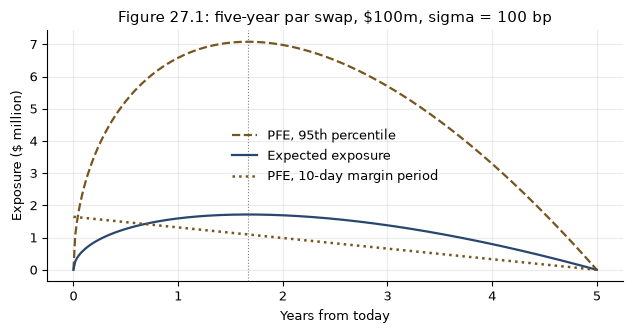

In [2]:
T, SIG, NOTIONAL, Q95, MPOR = 5.0, 0.01, 100.0, 1.645, 10           # 1.645 as the chapter writes it
EZ = 1 / sqrt(2 * pi)                          # E[Z+] for a standard normal Z


def pfe(t):
    return NOTIONAL * SIG * (T - t) * np.sqrt(t) * Q95


def ee(t):
    return NOTIONAL * SIG * (T - t) * np.sqrt(t) * EZ


def pfe_margined(t):
    return NOTIONAL * SIG * (T - t) * sqrt(MPOR / 250) * Q95


hump = minimize_scalar(lambda t: -(T - t) * sqrt(t), bounds=(0, T), method="bounded").x
show("hump of (T - t) sqrt(t), years (T/3)", hump, T / 3, 1e-4)
show("PFE at the hump, $m", pfe(T / 3), 7.08)
show("EE at the hump, $m", ee(T / 3), 1.72)
show("PFE / EE, N^-1(0.95) sqrt(2 pi)", Q95 / EZ, 4.12)
show("margined PFE at inception, $m", pfe_margined(0.0), 1.65, 6e-3)

# EEPE: EE averaged over the first year, using the running maximum; EE is still rising at
# one year because the hump is at T/3 > 1, so the running maximum is EE itself
eepe = quad(ee, 0, 1)[0]
show("EEPE, $m", eepe, 1.17)
show("alpha x EEPE, $m", 1.4 * eepe, 1.64)

# with 5% flat discounting the annuity is (1 - e^{-r(T-t)})/r rather than T - t
R = 0.05
g = lambda t: (1 - exp(-R * (T - t))) / R * sqrt(t)
peak = minimize_scalar(lambda t: -g(t), bounds=(0, T), method="bounded").x
show("peak with 5% discounting, years", peak, 1.76, 0.01)
show("height fall with 5% discounting, %", 100 * (1 - g(peak) / ((T - T / 3) * sqrt(T / 3))), 7.8, 0.3)

t = np.linspace(0, T, 301)
fig, ax = plt.subplots()
ax.plot(t, pfe(t), "--", color=AMBER, lw=1.6, label="PFE, 95th percentile")
ax.plot(t, ee(t), "-", color=BLUE, lw=1.6, label="Expected exposure")
ax.plot(t, pfe_margined(t), ":", color=AMBER, lw=1.8, label="PFE, 10-day margin period")
ax.axvline(T / 3, color="gray", lw=0.8, ls=":")
ax.set_xlabel("Years from today"); ax.set_ylabel("Exposure ($ million)")
ax.set_title("Figure 27.1: five-year par swap, $100m, sigma = 100 bp")
ax.legend(frameon=False)
plt.tight_layout(); plt.show()

## 2. What netting is worth — Example 27.1

Without an enforceable netting agreement the counterparty's administrator enforces the trades it is
owed on and pays only a recovery fraction on the rest, so the exposure is the sum of the positive
values. With netting it is the net value. The same five trades show both, and the second line of the
cell shows that netting is a property of the set: one new trade can lower the exposure, which no new
loan ever does.

In [3]:
def exposure(marks, netted=True):
    return max(sum(marks), 0.0) if netted else sum(m for m in marks if m > 0)


BOOK = [40, -35, 20, -15, -8]                  # Example 1.1's book, $m
show("gross exposure, $m", exposure(BOOK, netted=False), 60)
show("net exposure, $m", exposure(BOOK), 2)
show("reduction, %", 100 * (1 - exposure(BOOK) / exposure(BOOK, netted=False)), 97, 0.5)
print()
print("add one trade worth -2 to the bank: gross stays %.0f, net falls to %.0f"
      % (exposure(BOOK + [-2], netted=False), exposure(BOOK + [-2])))

gross exposure, $m                                 60.00000   book    60.00000   ok
net exposure, $m                                    2.00000   book     2.00000   ok
reduction, %                                       96.66667   book    97.00000   ok

add one trade worth -2 to the bank: gross stays 60, net falls to 0


## 3. SA-CCR on one swap — Example 27.2

The calculator below follows the chapter's equations for an interest-rate netting set in one
currency: replacement cost (27.2) or (27.3), each trade's effective notional (27.5) from its
supervisory delta, duration (27.6) and maturity factor (27.7), the three maturity buckets combined
by (27.8), the add-on (27.9), the multiplier (27.10), and $\text{EAD} = 1.4(\text{RC} + \text{PFE})$.

Run on Example 27.2's swap it gives every figure the example prints. Out of the money by \$5 million,
the swap still carries about a third of its at-the-money exposure, because rates can move far
enough to swing it the bank's way. Under daily margin the add-on falls 70%, purely from the maturity
factor.

In [4]:
SF_IR, ALPHA = 0.005, 1.4


def supervisory_duration(start, end):
    """Eq. (27.6)."""
    return (exp(-0.05 * start) - exp(-0.05 * end)) / 0.05


def maturity_factor(remaining, mpor=None):
    """Eq. (27.7): unmargined, or margined with an MPOR in business days, capped at one."""
    if mpor is None:
        return sqrt(min(max(remaining, 10 / 250), 1.0))
    return min(1.5 * sqrt(mpor / 250), 1.0)


def bucket(end):
    return 0 if end < 1 else (1 if end <= 5 else 2)


def ir_effective_notional(trades, mpor=None):
    """Eqs. (27.5) and (27.8). A trade is (delta, start, end, notional)."""
    D = [0.0, 0.0, 0.0]
    for delta, start, end, notional in trades:
        D[bucket(end)] += delta * supervisory_duration(start, end) * maturity_factor(end, mpor) * notional
    d1, d2, d3 = D
    return sqrt(d1 ** 2 + d2 ** 2 + d3 ** 2 + 1.4 * d1 * d2 + 1.4 * d2 * d3 + 0.6 * d1 * d3)


def saccr(trades, V=0.0, C=0.0, mpor=None, TH=0.0, MTA=0.0, NICA=0.0):
    """EAD = alpha (RC + PFE), eqs. (27.1)-(27.10), for one interest-rate hedging set."""
    addon = SF_IR * ir_effective_notional(trades, mpor)
    rc = max(V - C, 0.0) if mpor is None else max(V - C, TH + MTA - NICA, 0.0)
    mult = 1.0 if addon == 0 else min(1.0, 0.05 + 0.95 * exp((V - C) / (2 * 0.95 * addon)))
    return {"RC": rc, "AddOn": addon, "mult": mult, "PFE": mult * addon,
            "EAD": ALPHA * (rc + mult * addon)}


SWAP = [(+1, 0.0, 5.0, 100.0)]                 # pay fixed, five years, $100m
show("supervisory duration, 5y", supervisory_duration(0, 5), 4.4240, 5e-5)
show("effective notional D, $m", ir_effective_notional(SWAP), 442.40)
for label, V, mpor, want in (("at zero MtM", 0.0, None, 3.10), ("$5m in the money", 5.0, None, 10.10),
                             ("$5m out of the money", -5.0, None, 1.05), ("margined, 10 days", 0.0, 10, 0.93)):
    r = saccr(SWAP, V=V, mpor=mpor)
    show("EAD %s, $m" % label, r["EAD"], want)
r = saccr(SWAP, V=-5.0)
show("  multiplier out of the money", r["mult"], 0.339, 5e-4)
show("  PFE out of the money, $m", r["PFE"], 0.75)
show("add-on, unmargined, $m", saccr(SWAP)["AddOn"], 2.212, 5e-4)
show("add-on, margined, $m", saccr(SWAP, mpor=10)["AddOn"], 0.664, 5e-4)
show("add-on reduction from margining, %", 100 * (1 - saccr(SWAP, mpor=10)["AddOn"] / saccr(SWAP)["AddOn"]), 70, 1e-9)
print()
print("dollars per basis point carried by the effective notional: %.0f" % (ir_effective_notional(SWAP) * 1e6 * 1e-4))

supervisory duration, 5y                            4.42398   book     4.42400   ok
effective notional D, $m                          442.39843   book   442.40000   ok
EAD at zero MtM, $m                                 3.09679   book     3.10000   ok
EAD $5m in the money, $m                           10.09679   book    10.10000   ok
EAD $5m out of the money, $m                        1.05012   book     1.05000   ok
EAD margined, 10 days, $m                           0.92904   book     0.93000   ok
  multiplier out of the money                       0.33910   book     0.33900   ok
  PFE out of the money, $m                          0.75009   book     0.75000   ok
add-on, unmargined, $m                              2.21199   book     2.21200   ok
add-on, margined, $m                                0.66360   book     0.66400   ok
add-on reduction from margining, %                 70.00000   book    70.00000   ok

dollars per basis point carried by the effective notional: 44240


### The multiplier is fitted to a normal expectation

The chapter says the multiplier is a floored exponential fitted to the exact expectation for a
position that starts out of the money. Under the same driftless normal model, with the add-on
playing the role of $\varphi(0)$ times the standard deviation, the exact ratio of expected exposure
to its at-the-money value is $\big(m\,N(m/s) + s\,\varphi(m/s)\big)/(s\,\varphi(0))$ for a mark-to-market
$m$. The supervisory form is tangent to it at $m = 0$ and sits above it for out-of-the-money sets:
0.339 against an exact 0.251 at Example 27.2's $-\$5$ million. The 5% floor then keeps a deeply
out-of-the-money set from being credited with almost no exposure.

exact ratio at -$5m                                 0.25093   book     0.25100   ok
supervisory multiplier at -$5m                      0.33910   book     0.33900   ok


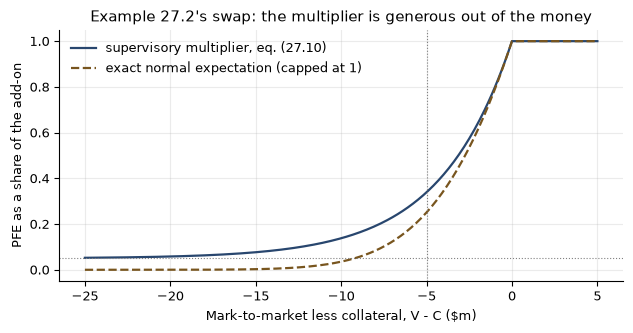

In [5]:
addon = saccr(SWAP)["AddOn"]
s = addon / phi(0)                             # the standard deviation the add-on implies
m = np.linspace(-25, 5, 301)
exact = (m * N(m / s) + s * phi(m / s)) / (s * phi(0))
supervisory = np.minimum(1.0, 0.05 + 0.95 * np.exp(m / (2 * 0.95 * addon)))
show("exact ratio at -$5m", float((-5 * N(-5 / s) + s * phi(-5 / s)) / (s * phi(0))), 0.251, 5e-4)
show("supervisory multiplier at -$5m", saccr(SWAP, V=-5.0)["mult"], 0.339, 5e-4)

fig, ax = plt.subplots()
ax.plot(m, supervisory, "-", color=BLUE, lw=1.6, label="supervisory multiplier, eq. (27.10)")
ax.plot(m, np.minimum(exact, 1.0), "--", color=AMBER, lw=1.6, label="exact normal expectation (capped at 1)")
ax.axhline(0.05, color="gray", lw=0.8, ls=":")
ax.axvline(-5, color="gray", lw=0.8, ls=":")
ax.set_xlabel("Mark-to-market less collateral, V - C ($m)")
ax.set_ylabel("PFE as a share of the add-on")
ax.set_title("Example 27.2's swap: the multiplier is generous out of the money")
ax.legend(frameon=False, loc="upper left")
plt.tight_layout(); plt.show()

## 4. The maturity factor and partial offset

The margined maturity factor $1.5\sqrt{\text{MPOR}/250}$ reaches the unmargined value of one at
$250/1.5^2 = 111$ business days, so beyond about five months of close-out risk margining buys no
add-on relief. A position that genuinely takes thirty days to unwind keeps 52% of the unmargined
add-on even under a daily margin agreement.

Across maturity buckets the offset is partial. A payer of 100 in the one-to-five-year bucket against
a receiver of 100 in the over-five-year bucket counts as 77: neither the 0 of a perfect hedge nor
the 141 of none. Within a bucket the offset is complete. The second cell shows both with real
trades.

MPOR at which MF = 1, business days               111.11111   book   111.00000   ok
MF at 10 days                                       0.30000   book     0.30000   ok
MF at 30 days                                       0.51962   book     0.52000   ok
+100 against -100 across adjacent buckets          77.45967   book    77.00000   ok
  with no offset at all                           141.42136   book   141.00000   ok


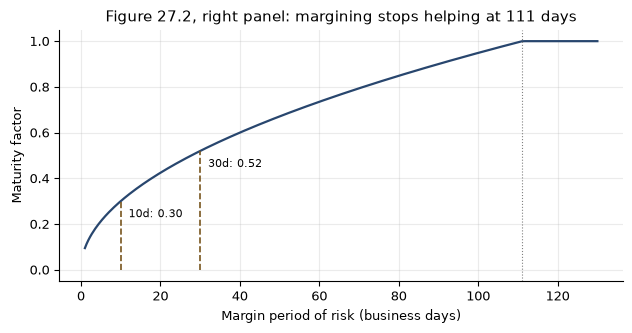

In [6]:
show("MPOR at which MF = 1, business days", 250 / 1.5 ** 2, 111, 0.2)
show("MF at 10 days", maturity_factor(5, 10), 0.30, 1e-9)
show("MF at 30 days", maturity_factor(5, 30), 0.52, 5e-3)
cross = sqrt(100 ** 2 + 100 ** 2 - 2 * 0.7 * 100 * 100)
show("+100 against -100 across adjacent buckets", cross, 77, 0.5)
show("  with no offset at all", sqrt(2) * 100, 141, 0.5)

mp = np.linspace(1, 130, 300)
fig, ax = plt.subplots()
ax.plot(mp, [maturity_factor(5, x) for x in mp], "-", color=BLUE, lw=1.6)
for x in (10, 30):
    ax.plot([x, x], [0, maturity_factor(5, x)], "--", color=AMBER, lw=1.2)
    ax.text(x + 2, maturity_factor(5, x) - 0.07, "%dd: %.2f" % (x, maturity_factor(5, x)), fontsize=8)
ax.axvline(111, color="gray", lw=0.8, ls=":")
ax.set_xlabel("Margin period of risk (business days)"); ax.set_ylabel("Maturity factor")
ax.set_title("Figure 27.2, right panel: margining stops helping at 111 days")
plt.tight_layout(); plt.show()

In [7]:
# real trades: the payer bucket is 1-5 years, the receivers sit within it or beyond it
payer = (+1, 0.0, 5.0, 100.0)
recv_same = (-1, 0.0, 4.0, 100.0 * supervisory_duration(0, 5) / supervisory_duration(0, 4))
recv_long = (-1, 0.0, 7.0, 100.0 * supervisory_duration(0, 5) / supervisory_duration(0, 7))
for label, book in (("payer alone", [payer]),
                    ("+ receiver, same bucket, same DV01", [payer, recv_same]),
                    ("+ receiver, next bucket, same DV01", [payer, recv_long])):
    print("%-38s EN = %7.2f   EAD = %5.2f" % (label, ir_effective_notional(book), saccr(book)["EAD"]))
print()
print("the cross-bucket hedge removes %.0f%% of the add-on; the same hedge inside the bucket removes all of it"
      % (100 * (1 - ir_effective_notional([payer, recv_long]) / ir_effective_notional([payer]))))

payer alone                            EN =  442.40   EAD =  3.10
+ receiver, same bucket, same DV01     EN =    0.00   EAD =  0.00
+ receiver, next bucket, same DV01     EN =  342.68   EAD =  2.40

the cross-bucket hedge removes 23% of the add-on; the same hedge inside the bucket removes all of it


## 5. Capital under three regimes — Example 27.3

Capital is EAD times the counterparty's risk weight times the capital ratio, 10.5% here. Margining
cuts EAD by 70%, and clearing keeps that ten-day floor and then applies a 2% risk weight, a further
factor of fifty. The ratio is 167 : 50 : 1. At a 10% hurdle the running charge is 3.25 basis points a
year uncleared and unmargined against 0.02 cleared, which on a swap quoted at a fraction of a basis
point of bid–ask is decisive.

The default-fund charge the table omits does not change the ordering: its floor adds \$21 per swap
against the \$96,000 clearing saves on each margined uncleared one.

In [8]:
CR, HURDLE = 0.105, 0.10
rows = (("Uncleared, unmargined", saccr(SWAP)["EAD"], 1.00, 0.3252),
        ("Uncleared, margined (10d)", saccr(SWAP, mpor=10)["EAD"], 1.00, 0.0975),
        ("Cleared at a QCCP (10d)", saccr(SWAP, mpor=10)["EAD"], 0.02, 0.00195))
print("%-28s %8s %8s %8s %10s %12s" % ("", "EAD", "RW", "RWA", "capital", "bp a year"))
cap = {}
for label, ead, rw, want in rows:
    cap[label] = ead * rw * CR                    # eq. (27.11)
    print("%-28s %8.3f %7.0f%% %8.3f %10.5f %12.2f"
          % (label, ead, 100 * rw, ead * rw, cap[label], 1e4 * HURDLE * cap[label] / 100))
    show("  capital, " + label, cap[label], want, 5e-5)
c_u, c_m, c_c = cap.values()
show("ratio unmargined : cleared", c_u / c_c, 167, 0.5)
show("ratio margined : cleared", c_m / c_c, 50, 0.5)
show("cleared as % of unmargined", 100 * c_c / c_u, 0.6, 0.05)
print()
df_floor = 0.02 * 100.0 * CR                     # 2% RW on a $100m default-fund contribution
show("default-fund floor, $m", df_floor, 0.21, 1e-9)
show("  per swap over 10,000 swaps, $", 1e6 * df_floor / 10000, 21.0, 1e-9)
show("clearing saves per margined uncleared swap, $", 1e6 * (c_m - c_c), 96000, 500)

                                  EAD       RW      RWA    capital    bp a year
Uncleared, unmargined           3.097     100%    3.097    0.32516         3.25
  capital, Uncleared, unmargined                    0.32516   book     0.32520   ok
Uncleared, margined (10d)       0.929     100%    0.929    0.09755         0.98
  capital, Uncleared, margined (10d)                0.09755   book     0.09750   ok
Cleared at a QCCP (10d)         0.929       2%    0.019    0.00195         0.02
  capital, Cleared at a QCCP (10d)                  0.00195   book     0.00195   ok
ratio unmargined : cleared                        166.66667   book   167.00000   ok
ratio margined : cleared                           50.00000   book    50.00000   ok
cleared as % of unmargined                          0.60000   book     0.60000   ok

default-fund floor, $m                              0.21000   book     0.21000   ok
  per swap over 10,000 swaps, $                    21.00000   book    21.00000   ok
clearin

## 6. Where SA-CCR and the internal model meet — alpha

The supervisory factor of 0.50% is a one-year EEPE at a stressed normal volatility, about 188 basis
points a year. At that volatility Example 27.2's swap has an EEPE of \$2.20 million, which $\alpha$
takes to \$3.08 million against SA-CCR's \$3.10 million. The two routes are built to meet on a plain
swap.

$\alpha = 1.4$ is not a measurement that exposures are 40% larger than they look. It is a buffer for
what a loan-equivalent misses (correlation between exposures and defaults, and concentration),
which industry studies put nearer 1.1 for diversified books.

In [9]:
sig_stressed = SF_IR * 1.5 * sqrt(2 * pi)        # the normal vol behind SF = 0.50%
show("normal vol behind the supervisory factor, bp", 1e4 * sig_stressed, 188, 0.5)
eepe_s = quad(lambda t: NOTIONAL * sig_stressed * (T - t) * sqrt(t) * EZ, 0, 1)[0]
show("internal-model EEPE at that vol, $m", eepe_s, 2.20)
show("alpha x EEPE, $m", ALPHA * eepe_s, 3.08)
show("SA-CCR EAD, $m", saccr(SWAP)["EAD"], 3.10)

normal vol behind the supervisory factor, bp      187.99712   book   188.00000   ok
internal-model EEPE at that vol, $m                 2.20000   book     2.20000   ok
alpha x EEPE, $m                                    3.08000   book     3.08000   ok
SA-CCR EAD, $m                                      3.09679   book     3.10000   ok


## 7. What wrong-way correlation costs — Example 27.4

CVA under independence is loss given default times default probability times expected exposure.
Wrong-way risk replaces the average exposure by the exposure conditional on default, so the charge
scales linearly with their ratio. The calculation contains no correlation parameter at all; the ratio
is the whole input, and it is a conditional expectation on an event that has never happened for this
counterparty.

In [10]:
LGD, PD, EXPO = 0.60, 0.03, 10.0
cva0 = LGD * PD * EXPO
show("CVA under independence, $m", cva0, 0.18, 1e-9)
show("conditional exposure doubled, $m", LGD * PD * 2 * EXPO, 0.36, 1e-9)
print()
print("%28s %10s" % ("E[exposure | default] / EE", "CVA, $m"))
for k in (1.0, 1.25, 1.5, 2.0, 3.0):
    print("%28.2f %10.3f" % (k, k * cva0))

CVA under independence, $m                          0.18000   book     0.18000   ok
conditional exposure doubled, $m                    0.36000   book     0.36000   ok

  E[exposure | default] / EE    CVA, $m
                        1.00      0.180
                        1.25      0.225
                        1.50      0.270
                        2.00      0.360
                        3.00      0.540


## 8. The leverage ratio crossover, and a bank's capital stack — Example 27.5

A trade costs the larger of $\text{EAD}\times\text{LR}$ and $\text{EAD}\times\text{RW}\times\text{CR}$, so
the leverage ratio binds whenever the risk weight is below $\text{LR}/\text{CR}$: 29% at the 3%
baseline and a 10.5% capital ratio. Sovereigns, qualifying CCPs and highly rated banks all fall below
it, which is why the leverage ratio bites hardest on the safest businesses.

Example 27.5 applies the same comparison to a whole bank. Its average risk weight, 34%, is below the
35.7% at which a G-SIB's 3.75% leverage requirement and its 10.5% tier 1 requirement cost the same,
so leverage binds, and a desk that lowered its risk weights would save nothing.

In [11]:
print("%-24s %s" % ("leverage requirement", "binds below a risk weight of"))
for lr, want in ((0.03, 29), (0.05, 48), (0.06, 57)):
    print("%-24s %5.1f%%" % ("%.0f%%" % (100 * lr), 100 * lr / CR))
    show("  crossover at LR %.0f%%, %%" % (100 * lr), 100 * lr / CR, want, 0.6)
print()

RWA = {"credit": 600, "counterparty": 40, "CVA": 30, "market": 60, "operational": 100, "securitization": 20}
total = sum(RWA.values())
buffers = 2.5 + 1.5 + 0.5                        # conservation, G-SIB surcharge, countercyclical
show("total RWA, $bn", total, 850, 1e-9)
for name, minimum, want in (("CET1", 4.5, 76.50), ("tier 1", 6.0, 89.25), ("total capital", 8.0, 106.25)):
    show("%s requirement, $bn" % name, (minimum + buffers) / 100 * total, want, 1e-9)
leverage = (3.0 + 1.5 / 2) / 100 * 2500          # 3% plus half the surcharge, on $2,500bn
show("G-SIB leverage requirement, $bn", leverage, 93.75, 1e-9)
show("average risk weight, %", 100 * total / 2500, 34.0, 1e-9)
show("crossover 3.75 / 10.5, %", 100 * 3.75 / 10.5, 35.7, 0.05)
print("binding constraint:", "leverage ratio" if leverage > (6.0 + buffers) / 100 * total else "risk-based tier 1")
show("counterparty + CVA share of RWA, %", 100 * (RWA["counterparty"] + RWA["CVA"]) / total, 8.2, 0.05)
show("undrawn $200m BBB facility: RWA, $m", 200 * 0.40 * 0.75, 60, 1e-9)

leverage requirement     binds below a risk weight of
3%                        28.6%
  crossover at LR 3%, %                            28.57143   book    29.00000   ok
5%                        47.6%
  crossover at LR 5%, %                            47.61905   book    48.00000   ok
6%                        57.1%
  crossover at LR 6%, %                            57.14286   book    57.00000   ok

total RWA, $bn                                    850.00000   book   850.00000   ok
CET1 requirement, $bn                              76.50000   book    76.50000   ok
tier 1 requirement, $bn                            89.25000   book    89.25000   ok
total capital requirement, $bn                    106.25000   book   106.25000   ok
G-SIB leverage requirement, $bn                    93.75000   book    93.75000   ok
average risk weight, %                             34.00000   book    34.00000   ok
crossover 3.75 / 10.5, %                           35.71429   book    35.70000   ok
binding c

## 9. What a CDS hedge does to a loan's capital — Example 27.6

Protection works by substitution: the protected part of the loan takes the protection seller's risk
weight. A CDS that omits restructuring is recognized at 60%, and protection shorter than the loan in
proportion to $(t - 0.25)/(T - 0.25)$. The full hedge saves \$8.40 million of capital, worth 84 basis
points a year at a 10% hurdle, so for a borrower whose CDS trades below that the capital relief pays
for the hedge on its own.

The plot shows how the relief builds with the protection's tenor, and why protection with three
months or less to run is worth nothing.

capital, unhedged, $m                              10.50000   book    10.50000   ok
capital, full hedge, $m                             2.10000   book     2.10000   ok
capital, no restructuring (60% recognized), $m      5.46000   book     5.46000   ok
capital, three-year CDS, $m                         5.63684   book     5.64000   ok
three-year CDS: recognized amount, $m              57.89474   book    57.89000   ok
capital saved by the full hedge, $m                 8.40000   book     8.40000   ok
  worth at a 10% hurdle, bp of the loan            84.00000   book    84.00000   ok
cash collateral of $60m: RWA, $m                   40.00000   book    40.00000   ok


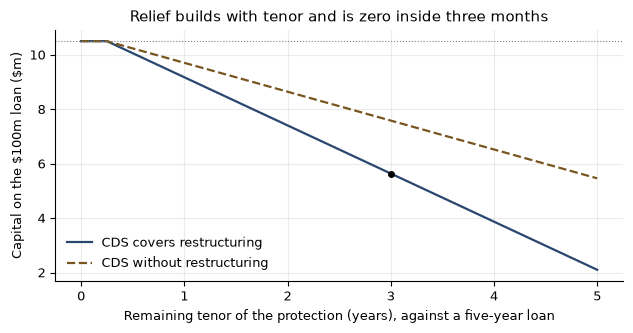

In [12]:
LOAN, RW_BORROWER, RW_SELLER, LOAN_T = 100.0, 1.00, 0.20, 5.0


def hedged_rwa(protected, t_cds=LOAN_T, T=LOAN_T):
    """Substitution, with the maturity-mismatch haircut (t - 0.25)/(T - 0.25)."""
    if t_cds <= 0.25:
        recognized = 0.0
    else:
        recognized = protected * min(1.0, (t_cds - 0.25) / (min(T, 5.0) - 0.25))
    return recognized * RW_SELLER + (LOAN - recognized) * RW_BORROWER


for label, rwa, want in (("unhedged", LOAN * RW_BORROWER, 10.50),
                         ("full hedge", hedged_rwa(LOAN), 2.10),
                         ("no restructuring (60% recognized)", hedged_rwa(0.60 * LOAN), 5.46),
                         ("three-year CDS", hedged_rwa(LOAN, t_cds=3.0), 5.64)):
    show("capital, %s, $m" % label, CR * rwa, want)
show("three-year CDS: recognized amount, $m", LOAN * (3 - 0.25) / (5 - 0.25), 57.89)
saved = CR * (LOAN * RW_BORROWER - hedged_rwa(LOAN))
show("capital saved by the full hedge, $m", saved, 8.40, 1e-9)
show("  worth at a 10% hurdle, bp of the loan", 1e4 * HURDLE * saved / LOAN, 84, 1e-9)
show("cash collateral of $60m: RWA, $m", max(0.0, LOAN - 60.0) * RW_BORROWER, 40, 1e-9)

tc = np.linspace(0, 5, 201)
fig, ax = plt.subplots()
ax.plot(tc, [CR * hedged_rwa(LOAN, t_cds=x) for x in tc], "-", color=BLUE, lw=1.6,
        label="CDS covers restructuring")
ax.plot(tc, [CR * hedged_rwa(0.6 * LOAN, t_cds=x) for x in tc], "--", color=AMBER, lw=1.6,
        label="CDS without restructuring")
ax.axhline(CR * LOAN, color="gray", lw=0.8, ls=":")
ax.plot([3.0], [CR * hedged_rwa(LOAN, t_cds=3.0)], "o", color="black", ms=4)
ax.set_xlabel("Remaining tenor of the protection (years), against a five-year loan")
ax.set_ylabel(r"Capital on the \$100m loan (\$m)")
ax.set_title("Relief builds with tenor and is zero inside three months")
ax.legend(frameon=False)
plt.tight_layout(); plt.show()

## 10. The Archegos arithmetic

The stylized fund: \$10 billion of capital, five times leverage through total return swaps, split
across six prime brokers each holding 15% initial margin on its slice. Each broker sees an
unremarkable \$8.3 billion. The client's capital is gone at a 20% move, and at 30% each broker holds
\$1.25 billion of margin against a \$2.5 billion loss.

The plot is the point no bilateral measure can see: each broker's shortfall depends on a move it
cannot size, because the leverage that sets it is spread across five other balance sheets.

what each broker sees, $bn                          8.33333   book     8.30000   ok
initial margin per broker, $bn                      1.25000   book     1.25000   ok
move that exhausts the client's capital, %         20.00000   book    20.00000   ok
loss on gross at -10%, $bn                          5.00000   book     5.00000   ok
loss on gross at -20%, $bn                         10.00000   book    10.00000   ok
loss on gross at -30%, $bn                         15.00000   book    15.00000   ok
shortfall per broker at -30%, margin only, $bn      1.25000   book     1.25000   ok
total shortfall if all capital collected, $bn       5.00000   book     5.00000   ok


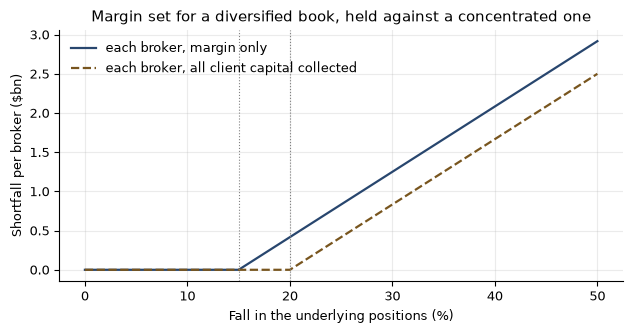

In [13]:
CAPITAL, LEVERAGE, BROKERS, IM = 10.0, 5, 6, 0.15
gross = CAPITAL * LEVERAGE
each = gross / BROKERS
margin = IM * each
show("what each broker sees, $bn", each, 8.3, 0.05)
show("initial margin per broker, $bn", margin, 1.25, 1e-9)
show("move that exhausts the client's capital, %", 100 * CAPITAL / gross, 20, 1e-9)
for move, want in ((0.10, 5.0), (0.20, 10.0), (0.30, 15.0)):
    show("loss on gross at -%.0f%%, $bn" % (100 * move), move * gross, want, 1e-9)
show("shortfall per broker at -30%, margin only, $bn", 0.30 * gross / BROKERS - margin, 1.25, 1e-9)
show("total shortfall if all capital collected, $bn", 0.30 * gross - CAPITAL, 5.0, 1e-9)

mv = np.linspace(0, 0.5, 201)
fig, ax = plt.subplots()
ax.plot(100 * mv, np.maximum(mv * gross / BROKERS - margin, 0), "-", color=BLUE, lw=1.6,
        label="each broker, margin only")
ax.plot(100 * mv, np.maximum(mv * gross - CAPITAL, 0) / BROKERS, "--", color=AMBER, lw=1.6,
        label="each broker, all client capital collected")
ax.axvline(100 * IM, color="gray", lw=0.8, ls=":")
ax.axvline(100 * CAPITAL / gross, color="gray", lw=0.8, ls=":")
ax.set_xlabel("Fall in the underlying positions (%)"); ax.set_ylabel("Shortfall per broker ($bn)")
ax.set_title("Margin set for a diversified book, held against a concentrated one")
ax.legend(frameon=False)
plt.tight_layout(); plt.show()

## What reproduced, and what to take from it

If the cell below reports that every figure reproduces, the notebook matches the chapter.

Two habits are worth carrying out of here. **Find the constraint that binds before pulling a
lever**: margining, clearing, risk weights and hedges each move a different term, and which of them
saves capital depends on whether the risk-based ratio, the leverage ratio or the floor binds. And
**ask what an input assumes**: the ten-day margin period, the 15% initial margin and the bilateral
view are each a claim about liquidity or visibility, and Archegos is what happens when all three are
wrong at once.

In [14]:
if BAD:
    print("%d figure(s) differ from the chapter:" % len(BAD))
    for b in BAD:
        print("   ", b)
else:
    print("every figure in this notebook reproduces the chapter")

every figure in this notebook reproduces the chapter
